# EGCG ligand-based shape-matching RL

Reinforcement learning on a **Papyrus pretrained SMILES-RNN**, driven by 3D
shape + colour similarity to a single reference molecule, **EGCG**
(epigallocatechin gallate), plus synthetic accessibility.

**What this is**

- **No supervised fine-tuning.** Agent and prior are both the unmodified Papyrus
  checkpoint. RL *does* update the agent's weights — that is the mechanism under
  test. "No transfer learning" here means no supervised stage, not "untrained".
- **No scaffold constraint.** EGCG is a 3D *scoring reference*, not a required
  substructure. (Its Bemis–Murcko scaffold covers 25 of 33 heavy atoms, so
  scaffold conditioning would pre-determine most of the molecule.)
- **RDKit backend only**, single reference, `ParetoCrowdingDistance`, one seed.
  A descriptive pilot — no significance testing, no causal claims.

**Thresholds are reporting criteria, not optimization parameters.**
`ParetoCrowdingDistance` does not use thresholds to compute rewards, and this
notebook disables threshold-driven checkpoint selection and early stopping
(see the RL section). The ROCS and SA thresholds therefore set the `Desired`
flag and `desired_ratio`, and nothing else.

Design spec: `docs/superpowers/specs/2026-10-20-egcg-ligand-based-rl-design.md`.

## Gate 0 — provenance

The conda env installs `drugex` **editable against the main checkout**, which
sits on a branch that never ran in production. The editable finder also maps
`tutorial`, `docs` and `ccr2_gen`. So before anything is scored we *assert*
that every one of those resolves inside this worktree, and raise if not.

Hashes with a pinned expected value are **asserted**. Hashes without one are
**recorded** and labelled as such — logging a hash is not asserting against one.

In [1]:
import hashlib, json, os, platform, random, subprocess, sys, time
from pathlib import Path

# The interpreter itself is part of Gate 0. The drugex env's own `python3`
# kernelspec uses a BARE "python" in argv, so nbconvert can silently launch a
# different interpreter (base env) and fail on `import torch` with no hint that
# the kernel was wrong. Assert the interpreter before importing anything heavy.
EXPECTED_PREFIX = "/home/fulopj/miniconda3/envs/drugex"
if not sys.executable.startswith(EXPECTED_PREFIX):
    raise RuntimeError(
        f"Gate 0 FAILED: wrong interpreter.\n  running  {sys.executable}\n"
        f"  expected {EXPECTED_PREFIX}/bin/python\n\n"
        "Use the 'egcg-drugex' kernel: "
        "jupyter nbconvert --ExecutePreprocessor.kernel_name=egcg-drugex"
    )

import numpy as np
import pandas as pd
import torch

NB_DIR = Path.cwd().resolve()
WORKTREE = NB_DIR.parents[3]
if str(NB_DIR) not in sys.path:
    sys.path.insert(0, str(NB_DIR))

import config_egcg as cfg

# --- assert the imported modules come from THIS worktree -------------------
import drugex, drugex.training.scorers.rocs_rdkit as _rocs

failures = []
for name, mod in [("drugex", drugex), ("rocs_rdkit", _rocs), ("config_egcg", cfg)]:
    loc = Path(getattr(mod, "__file__")).resolve()
    inside = str(loc).startswith(str(WORKTREE))
    print(f"  {name:12s} {'OK ' if inside else 'BAD'}  {loc}")
    if not inside:
        failures.append(f"{name} resolved to {loc}, outside {WORKTREE}")

if failures:
    raise RuntimeError(
        "Gate 0 FAILED — wrong code on sys.path:\n  " + "\n  ".join(failures)
        + f"\n\nRun with PYTHONPATH={WORKTREE}"
    )

# `optimization_mode` must NOT exist here. If it does, we are on the wrong tree.
import inspect
_params = inspect.signature(_rocs.RDKitROCSScorer.__init__).parameters
assert "optimization_mode" not in _params, (
    "Gate 0 FAILED: RDKitROCSScorer accepts optimization_mode, so this is NOT "
    "the feature/shape-matching line this experiment was written against."
)
print(f"\n  RDKitROCSScorer params: {list(_params)[1:]}")

  drugex       OK   /home/fulopj/drx-run/DrugEx/.worktrees/egcg/drugex/__init__.py
  rocs_rdkit   OK   /home/fulopj/drx-run/DrugEx/.worktrees/egcg/drugex/training/scorers/rocs_rdkit.py
  config_egcg  OK   /home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/config_egcg.py

  RDKitROCSScorer params: ['conformer_generator', 'references', 'score_type', 'use_colors', 'show_progress', 'n_jobs', 'inject_color', 'score_variant', 'color_ff']


In [2]:
# --- revision + hashes -----------------------------------------------------
def _git(*args):
    return subprocess.run(["git", "-C", str(WORKTREE), *args],
                          capture_output=True, text=True).stdout.strip()

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

PROVENANCE = {
    "timestamp": time.strftime("%Y-%m-%dT%H:%M:%S%z"),
    "host": platform.node(),
    "python": sys.version.split()[0],
    "executable": sys.executable,
    "kernel": os.environ.get("JPY_SESSION_NAME", "") or "interactive",
    "torch": torch.__version__,
    "worktree": str(WORKTREE),
    "branch": _git("rev-parse", "--abbrev-ref", "HEAD"),
    "commit": _git("rev-parse", "HEAD"),
    "dirty": bool(_git("status", "--porcelain")),
    "drugex_module": str(Path(drugex.__file__).resolve()),
    "config": cfg.summary(),
}
try:
    from rdkit import rdBase
    PROVENANCE["rdkit"] = rdBase.rdkitVersion
except Exception:
    pass

# Asserted vs recorded, stated explicitly per file.
for label, path, expected in [
    ("pretrained .pkg",   cfg.PRETRAINED_PKG,   cfg.PRETRAINED_SHA256["pkg"]),
    ("pretrained .vocab", cfg.PRETRAINED_VOCAB, cfg.PRETRAINED_SHA256["vocab"]),
    ("reference .sdf",    cfg.REFERENCE_SDF,    cfg.REFERENCE_SHA256),
]:
    if not Path(path).exists():
        raise FileNotFoundError(f"Gate 0 FAILED: {label} missing: {path}")
    actual = sha256(path)
    PROVENANCE.setdefault("hashes", {})[label] = actual
    if expected:
        if actual != expected:
            raise RuntimeError(
                f"Gate 0 FAILED: {label} hash mismatch.\n  expected {expected}"
                f"\n  actual   {actual}"
            )
        print(f"  {label:18s} ASSERTED  {actual[:16]}...")
    else:
        print(f"  {label:18s} RECORDED (not pinned)  {actual[:16]}...")

print(f"\n  branch {PROVENANCE['branch']} @ {PROVENANCE['commit'][:8]}"
      f"{' (DIRTY)' if PROVENANCE['dirty'] else ''}")
print("Gate 0 PASSED.")

if cfg.SMOKE:
    print("\n" + "!" * 70)
    print("!! EGCG_SMOKE=1 -- SMOKE TEST MODE")
    print("!! Sizes are shrunk to prove the code RUNS. Every number below is")
    print("!! scientifically MEANINGLESS: far too few samples and conformers.")
    print("!! Do not report, plot or cite any result from this run.")
    print("!" * 70)

  pretrained .pkg    ASSERTED  34dbc312454635e3...
  pretrained .vocab  ASSERTED  5da364a8b6466246...
  reference .sdf     ASSERTED  39bce6edd56e661c...

  branch egcg @ 96b7d4e2 (DIRTY)
Gate 0 PASSED.


In [3]:
# --- seeds -----------------------------------------------------------------
# drugex/ contains no seeding call and we do not modify it, so the seed is set
# here. Conformer embedding is already deterministic inside DrugEx
# (params.randomSeed = 0xc0ffee).
random.seed(cfg.SEED)
np.random.seed(cfg.SEED)
torch.manual_seed(cfg.SEED)
torch.cuda.manual_seed_all(cfg.SEED)

# --- worker counts (oversubscription guard) --------------------------------
# num_threads and n_jobs MULTIPLY. Conformer generation stays single-threaded;
# parallelism comes from the scorer's process pool only.
_alloc = int(os.environ.get("PBS_NCPUS", os.cpu_count() or 4))
N_JOBS = max(1, _alloc - 2)          # leave 2 CPUs free, per standing preference
for _v in ("OMP_NUM_THREADS", "MKL_NUM_THREADS", "OPENBLAS_NUM_THREADS"):
    os.environ[_v] = "1"

print(f"allocation {_alloc} CPUs -> scorer n_jobs={N_JOBS}, conformer threads="
      f"{cfg.CONFORMER_NUM_THREADS}")

cfg.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

allocation 64 CPUs -> scorer n_jobs=62, conformer threads=0


## The reference molecule

EGCG, built as a single lowest-energy conformer (ETKDGv3 + MMFF94, fixed seed).
The single-conformer choice is a stated assumption: EGCG's gallate ester admits
several low-energy geometries and this fixes one.

**Gate 1** (inside `build_reference.py`) requires exactly one parsable, 3D,
non-degenerate molecule with 33 heavy atoms.

In [4]:
from rdkit import Chem
from rdkit.Chem import Draw

import build_reference

ref_mol = build_reference.gate1(cfg.REFERENCE_SDF)
print("Gate 1 PASSED.")
desc = build_reference.describe(ref_mol)
PROVENANCE["reference_descriptors"] = desc
pd.Series(desc).to_frame("EGCG").style.set_caption("")

Gate 1 PASSED.


,EGCG
formula,C22H18O11
mw,458.380000
hbd,8
hba,11
tpsa,197.400000
heavy_atoms,33
rotatable_bonds,3
murcko_heavy_atoms,25
canonical_smiles,O=C(O[C@@H]1Cc2c(O)cc(O)cc2O[C@@H]1c1cc(O)c(O)c(O)c1)c1cc(O)c(O)c(O)c1


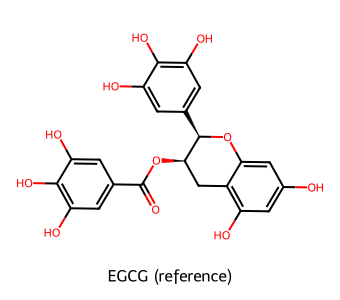

In [5]:
Draw.MolsToGridImage(
    [Chem.MolFromSmiles(desc["canonical_smiles"])],
    molsPerRow=1, subImgSize=(340, 300), legends=["EGCG (reference)"],
)

## Gate 2 — does the scoring path work?

Score EGCG against **itself**, plus a dissimilar control.

The nominal `TanimotoCombo` range is 0–2 (shape + colour), but **that range is
not achievable**: query conformers are generated independently of the reference
geometry, so even the reference molecule cannot recover its own pose. Measured
here, the EGCG self-score saturates at **~1.26** by 30 conformers (10 → 1.18,
30 → 1.26, 60 → 1.26). That is the practical ceiling for *any* molecule, and it
is why the threshold is calibrated from a baseline percentile rather than set to
a round number — an innocuous-looking cutoff of 1.0 is ~79% of the maximum.

In [6]:
env_probe = cfg.create_environment(rocs_threshold=cfg.ROCS_THRESHOLD_FALLBACK, n_jobs=N_JOBS)
ROCS_KEY = env_probe.getScorerKeys()[0]          # never hardcoded
print("scorer keys:", env_probe.getScorerKeys(), "\nROCS column:", ROCS_KEY)

_probe = env_probe.getScores([cfg.EGCG_SMILES, cfg.GATE2_CONTROL_SMILES])
self_score = float(_probe[ROCS_KEY].iloc[0])
ctrl_score = float(_probe[ROCS_KEY].iloc[1])
print(f"\n  EGCG self-score : {self_score:.4f}  (measured ceiling ~{cfg.SELF_SCORE_CEILING})")
print(f"  control         : {ctrl_score:.4f}  ({cfg.GATE2_CONTROL_SMILES})")

if self_score < cfg.GATE2_MIN_SELF_SCORE:
    raise RuntimeError(
        f"Gate 2 FAILED: self-score {self_score:.4f} < {cfg.GATE2_MIN_SELF_SCORE}. "
        "The scoring path is broken; no downstream number is meaningful."
    )
if ctrl_score > cfg.GATE2_MAX_CONTROL_SCORE:
    raise RuntimeError(
        f"Gate 2 FAILED: control scored {ctrl_score:.4f} > "
        f"{cfg.GATE2_MAX_CONTROL_SCORE} -- the scorer is not discriminating."
    )
PROVENANCE["gate2"] = {"self_score": self_score, "control_score": ctrl_score}
print("\nGate 2 PASSED.")

scorer keys: ['RDKit_Supermol_TanimotoCombo', 'SA'] 
ROCS column: RDKit_Supermol_TanimotoCombo



  EGCG self-score : 1.2597  (measured ceiling ~1.2597)
  control         : 0.2642  (c1ccccc1)

Gate 2 PASSED.


In [7]:
agent0, voc0 = cfg.load_agent()
print(f"vocabulary: {voc0.size} tokens | device: {agent0.device}")
print(f"cuda available: {torch.cuda.is_available()} | torch threads: {torch.get_num_threads()}")
PROVENANCE["device"] = str(agent0.device)

vocabulary: 95 tokens | device: cpu
cuda available: False | torch threads: 1


## Gate 4 — is scoring actually parallel?

`RDKitROCSScorer.getScores` wraps its alignment `Pool` in a `try/except` that
falls back to `_score_sequential` — and prints the warning **only when
`show_progress=True`**, which we deliberately leave off to keep the notebook
readable. A failed pool would therefore silently downgrade the entire run to one
core and still exit 0.

That is not hypothetical: job 14052 ran 190 requested cores at load average 1.00
for nine minutes before being killed. The cause there was a `num_threads=1`
misconfiguration (now fixed), but the blindness is structural, so this gate
measures throughput directly rather than trusting the setting.

Note what *cannot* be fixed by cores: conformer generation runs serially across
molecules in the main process at a measured ~4.6 s/molecule. Only alignment
scales with `n_jobs`.

In [8]:
# --- Gate 4: throughput sanity ---------------------------------------------
_probe_n = max(8, min(24, N_JOBS))
_probe_smiles = agent_probe_smiles = agent0.generate(
    num_samples=_probe_n, batch_size=_probe_n, drop_invalid=True,
    drop_duplicates=True, evaluator=None, progress=False)["SMILES"].tolist()

_t0 = time.time()
_ = env_probe.getScores(_probe_smiles)
_elapsed = time.time() - _t0
_per_mol = _elapsed / max(1, len(_probe_smiles))

# Expected: conformer generation (serial, ~MEASURED s/mol) plus alignment
# (parallel). If alignment silently went sequential, per-molecule cost rises
# well above the conformer floor.
_floor = cfg.MEASURED_CONFORMER_SECONDS_PER_MOL
_ceiling = _floor * 3.0
print(f"  probe           : {len(_probe_smiles)} molecules in {_elapsed:.1f} s")
print(f"  per molecule    : {_per_mol:.2f} s  (conformer floor ~{_floor:.2f} s)")
print(f"  scorer n_jobs   : {N_JOBS}   conformer threads: {cfg.CONFORMER_NUM_THREADS} (0=all)")

if _per_mol > _ceiling:
    raise RuntimeError(
        f"Gate 4 FAILED: {_per_mol:.2f} s/molecule exceeds {_ceiling:.2f} s "
        f"({_floor:.2f} s conformer floor x3). Alignment has probably fallen back "
        "to sequential scoring -- re-run the scorer with show_progress=True to "
        "surface the suppressed warning, and check worker count on the node "
        "(`ps -u $USER | grep -c ipykernel`, load average)."
    )
PROVENANCE["gate4"] = {"seconds_per_molecule": _per_mol, "n_jobs": N_JOBS,
                       "conformer_threads": cfg.CONFORMER_NUM_THREADS}
print("\nGate 4 PASSED.")

  probe           : 24 molecules in 66.8 s
  per molecule    : 2.78 s  (conformer floor ~4.58 s)
  scorer n_jobs   : 62   conformer threads: 0 (0=all)

Gate 4 PASSED.


## Sampling and scoring — one code path

Every arm (calibration, baseline, evaluation) goes through **this one function**,
so the measurement cannot differ between them.

Three details that the shipped tutorial gets wrong and that matter here:

1. `generate(evaluator=env)` concatenates **only** `env.getScorerKeys()` — it does
   *not* return `Valid` or `Desired`. We generate with `evaluator=None` and call
   `env.getScores()` ourselves.
2. `drop_invalid=False` skips `filterNewMolecules` entirely, so raw samples pass
   through unfiltered **and uncanonicalized** (`drop_duplicates` is inert on this
   path). Uniqueness is therefore computed by canonicalizing here.
3. Raw SA is scored with a **separate unmodified** `Property('SA')`, so the
   physical SA distribution costs nothing extra — a second `getScores()` would
   redo the expensive ROCS pass.

In [9]:
from drugex.training.scorers.properties import Property

raw_sa_scorer = cfg.create_raw_sa_scorer()

def sample_and_score(agent, env, n, label):
    """Generate n RAW samples and score them. Identical in every arm."""
    t0 = time.time()
    df = agent.generate(num_samples=n, batch_size=cfg.GEN_BATCH_SIZE,
                        drop_invalid=False, drop_duplicates=False,
                        evaluator=None, progress=False)
    smiles = df["SMILES"].tolist()

    scores = env.getScores(smiles)                 # Valid, Desired, ROCS, modified SA
    out = pd.DataFrame({"SMILES": smiles})
    for col in scores.columns:
        out[col] = scores[col].values

    # raw (physical) SAscore, valid molecules only -- no second ROCS pass
    mols = [Chem.MolFromSmiles(s) for s in smiles]
    raw_sa = np.full(len(smiles), np.nan)
    idx = [i for i, m in enumerate(mols) if m is not None]
    if idx:
        vals = raw_sa_scorer.getScores([mols[i] for i in idx])
        raw_sa[idx] = np.asarray(vals, dtype=float).ravel()
    out["SA_raw"] = raw_sa

    # cap violations ARE measurable from the structure itself, so cap-rejects
    # can be separated from other zeros.
    from rdkit.Chem import rdMolDescriptors as rdMD
    cap = np.zeros(len(smiles), dtype=bool)
    for i in idx:
        m = mols[i]
        cap[i] = (m.GetNumHeavyAtoms() > cfg.MAX_HEAVY_ATOMS
                  or rdMD.CalcNumRotatableBonds(m) > cfg.MAX_ROTATABLE_BONDS)
    out["cap_violation"] = cap

    out["canonical"] = [Chem.MolToSmiles(m) if m is not None else None for m in mols]
    out.attrs["label"] = label
    out.attrs["seconds"] = time.time() - t0
    print(f"  {label}: {len(out)} raw samples in {out.attrs['seconds']/60:.1f} min")
    return out


def metrics(df, rocs_key, rocs_threshold):
    """Metrics per spec 13. Shape over VALID molecules; rates over RAW samples."""
    n_raw = len(df)
    valid = df[df["Valid"] == 1]
    n_valid = len(valid)
    uniq = valid["canonical"].nunique()
    zero_valid = int((valid[rocs_key] <= 0.0).sum())
    return {
        "n_raw_samples": n_raw,
        "validity": n_valid / n_raw if n_raw else float("nan"),
        "uniqueness": uniq / n_raw if n_raw else float("nan"),
        "desired_ratio": float(df["Desired"].mean()),
        "median_rocs": float(valid[rocs_key].median()) if n_valid else float("nan"),
        "p90_rocs": float(valid[rocs_key].quantile(0.90)) if n_valid else float("nan"),
        "median_sa_raw": float(valid["SA_raw"].median()) if n_valid else float("nan"),
        "frac_of_ceiling": (float(valid[rocs_key].median()) / cfg.SELF_SCORE_CEILING
                            if n_valid else float("nan")),
        "n_invalid": n_raw - n_valid,
        "n_cap_violation": int(df["cap_violation"].sum()),
        "n_valid_but_zero": zero_valid,
        "rocs_threshold_used": rocs_threshold,
    }

## Stage 1a — calibration subset

A **separate** sample from the baseline evaluation subset. Calibrating the
threshold and measuring the baseline on the same molecules would make the
baseline `desired_ratio` a tautology of the chosen percentile.

**Gate 3** checks that this distribution is not degenerate before we calibrate
against it.

In [10]:
agent, voc = agent0, voc0
df_calib = sample_and_score(agent, env_probe, cfg.N_CALIBRATION, "calibration")
m_calib = metrics(df_calib, ROCS_KEY, cfg.ROCS_THRESHOLD_FALLBACK)
pd.Series(m_calib).to_frame("calibration subset")

  calibration: 1000 raw samples in 31.6 min


,calibration subset
n_raw_samples,1000.000000
validity,0.957000
uniqueness,0.957000
desired_ratio,0.001000
median_rocs,0.637714
p90_rocs,0.749263
median_sa_raw,2.592838
frac_of_ceiling,0.506243
n_invalid,43.000000
n_cap_violation,21.000000


In [11]:
# --- Gate 3: baseline coverage ---------------------------------------------
# NOT every zero is a conformer failure: invalid molecules are forced to 0.0,
# cap-rejected molecules score 0.0, and a genuinely dissimilar valid molecule
# can also score near 0. We separate what is separable and refuse to attribute
# the rest.
cov = m_calib["validity"]
print(f"  validity              : {cov:.3f}")
print(f"  invalid (forced 0)    : {m_calib['n_invalid']}")
print(f"  cap violations        : {m_calib['n_cap_violation']}  (measurable from structure)")
print(f"  valid but ROCS == 0   : {m_calib['n_valid_but_zero']}  "
      "(conformer failure OR total dissimilarity -- NOT attributable)")

if cov < 0.5:
    raise RuntimeError(
        f"Gate 3 FAILED: validity {cov:.3f} < 0.5. The calibration distribution "
        "is degenerate; any percentile taken from it is meaningless."
    )
_valid_calib = df_calib[df_calib["Valid"] == 1]
if float(_valid_calib[ROCS_KEY].max()) <= 0.0:
    raise RuntimeError("Gate 3 FAILED: no valid molecule scored above zero.")
print("\nGate 3 PASSED.")

  validity              : 0.957
  invalid (forced 0)    : 43
  cap violations        : 21  (measurable from structure)
  valid but ROCS == 0   : 34  (conformer failure OR total dissimilarity -- NOT attributable)

Gate 3 PASSED.


## Stage 2 — thresholds

The ROCS threshold is the chosen percentile of the **calibration** subset's raw
`TanimotoCombo`, over valid molecules. The SA threshold is derived from a
**physical raw-SAscore cutoff**, so the two can never disagree.

In [12]:
ROCS_THRESHOLD = float(np.percentile(_valid_calib[ROCS_KEY],
                                     cfg.ROCS_CALIBRATION_PERCENTILE))

print(f"  percentile            : {cfg.ROCS_CALIBRATION_PERCENTILE}")
print(f"  ROCS threshold (raw)  : {ROCS_THRESHOLD:.4f}  "
      f"({ROCS_THRESHOLD/cfg.SELF_SCORE_CEILING:.0%} of the measured ceiling)")
print(f"  raw SA cutoff         : {cfg.RAW_SA_CUTOFF}")
print(f"  SA threshold (modified): {cfg.SA_THRESHOLD:.4f}")
print(f"\n  for reference, the CCR2 campaign's SA_THRESHOLD=0.1 corresponds to "
      f"raw SAscore {cfg.CAMPAIGN_SA_THRESHOLD_RAW_EQUIVALENT:.4f}")

# Rebuild the environment with the calibrated threshold. Same scorer settings,
# same reference -- only the reporting threshold changes.
env = cfg.create_environment(rocs_threshold=ROCS_THRESHOLD, n_jobs=N_JOBS)
assert env.getScorerKeys()[0] == ROCS_KEY
PROVENANCE["thresholds"] = {
    "rocs_raw": ROCS_THRESHOLD,
    "rocs_percentile": cfg.ROCS_CALIBRATION_PERCENTILE,
    "sa_raw_cutoff": cfg.RAW_SA_CUTOFF,
    "sa_modified": cfg.SA_THRESHOLD,
}

  percentile            : 85.0
  ROCS threshold (raw)  : 0.7289  (58% of the measured ceiling)
  raw SA cutoff         : 4.5
  SA threshold (modified): 0.2689

  for reference, the CCR2 campaign's SA_THRESHOLD=0.1 corresponds to raw SAscore 5.0986


## Stage 1b — baseline evaluation subset

The comparator: a fresh sample from the **unmodified** pretrained agent, scored
with the calibrated environment.

In [13]:
df_baseline = sample_and_score(agent, env, cfg.N_BASELINE, "baseline")
m_baseline = metrics(df_baseline, ROCS_KEY, ROCS_THRESHOLD)

_bv = df_baseline[df_baseline["Valid"] == 1]
m_baseline_heavy = float(np.median([
    Chem.MolFromSmiles(x).GetNumHeavyAtoms()
    for x in _bv["canonical"] if Chem.MolFromSmiles(x) is not None
]))
print(f"  baseline median heavy atoms: {m_baseline_heavy:.0f}  (EGCG = {cfg.EGCG_HEAVY_ATOMS})")
pd.Series(m_baseline).to_frame("baseline")

  baseline: 10000 raw samples in 402.2 min


  baseline median heavy atoms: 27  (EGCG = 33)


,baseline
n_raw_samples,10000.000000
validity,0.955300
uniqueness,0.954600
desired_ratio,0.134200
median_rocs,0.642910
p90_rocs,0.749658
median_sa_raw,2.638969
frac_of_ceiling,0.510368
n_invalid,447.000000
n_cap_violation,170.000000


In [14]:
# --- cost projection --------------------------------------------------------
# PBS walltime is requested UP FRONT and cannot be extended, so this can only
# decide whether to proceed within the existing allocation.
sec_per_mol = df_baseline.attrs["seconds"] / max(1, len(df_baseline))
est_rl_min = sec_per_mol * cfg.RL_N_SAMPLES * cfg.RL_EPOCHS / 60
est_eval_min = sec_per_mol * cfg.N_EVALUATION / 60
print(f"  ~{sec_per_mol:.2f} s/molecule")
print(f"  projected RL   : ~{est_rl_min:.0f} min ({cfg.RL_EPOCHS} x {cfg.RL_N_SAMPLES})")
print(f"  projected eval : ~{est_eval_min:.0f} min")
print(f"  projected total: ~{(est_rl_min + est_eval_min)/60:.1f} h")
budget_h = float(os.environ.get("EGCG_BUDGET_HOURS", "0") or 0)
if budget_h and (est_rl_min + est_eval_min) / 60 > budget_h:
    raise RuntimeError(
        f"Projected {(est_rl_min+est_eval_min)/60:.1f} h exceeds the "
        f"{budget_h} h budget. Reduce RL_EPOCHS / RL_N_SAMPLES / MAX_CONFORMERS "
        "and resubmit -- PBS walltime cannot be extended."
    )

  ~2.41 s/molecule
  projected RL   : ~1236 min (60 x 512)
  projected eval : ~402 min
  projected total: ~27.3 h


## Stage 3 — reinforcement learning

**Decoupling the threshold from training.** `fit()` defaults would otherwise let
the calibrated threshold choose which weights survive:

| default | effect | our setting |
| --- | --- | --- |
| `criteria='desired_ratio'` | tracks best state by that metric | recorded, made inert |
| `reload_interval=50` | resets agent to best state every 50th epoch | `> epochs`, so never |
| `patience=50` | early stop on no improvement | `> epochs`, so never |
| `min_epochs=100` | floor before stopping | `= epochs` |

`FileMonitor` still writes a best-by-criterion `.pkg`. **That file is not the
evaluation artifact.** We save the actual final-epoch weights separately and
evaluate those.

### The exploration network must be a SEPARATE frozen prior

DrugEx documents `mutate` as "the **pre-trained** network which increases the
exploration of the chemical space", and `epsilon` as "the probability of using
the `mutate` network". In `SequenceRNN.evolve`, epsilon-selected rows take their
token probabilities from `mutate` instead of the agent.

Runs v1 and v2 passed `mutate=agent` — *the same object* — reasoning that "prior
== agent" expressed the no-fine-tuning design. That was a bug: exploration then
draws from the same network that RL is collapsing, so **`epsilon` had no effect
at all**. Measured on v2's final checkpoint, uniqueness stayed at 0.53 for every
epsilon from 0.0 to 0.6; with a separate frozen prior the same sweep gave 0.53 →
0.77 → 0.87 → 0.93.

"No supervised fine-tuning" is still honoured: the prior is the **unmodified
Papyrus checkpoint**, never trained. It is simply a *distinct, frozen instance*
rather than an alias of the agent.

In [15]:
from drugex.training.explorers import SequenceExplorer
from drugex.training.monitors import FileMonitor

# SEPARATE, FROZEN exploration prior -- not an alias of the agent (see above).
# Same Papyrus weights, never trained: the optimizer is built from
# agent.parameters() only, and these flags make that explicit and checkable.
prior, _ = cfg.load_agent()
for _p in prior.parameters():
    _p.requires_grad_(False)
prior.eval()
assert prior is not agent, "mutate must not be the agent -- epsilon would be inert"

def _fingerprint(model):
    """Order-stable hash of all parameters, for Gate 5."""
    h = hashlib.sha256()
    for name, t in sorted(model.state_dict().items()):
        h.update(name.encode())
        h.update(t.detach().cpu().numpy().tobytes())
    return h.hexdigest()

PRIOR_FINGERPRINT_BEFORE = _fingerprint(prior)
print(f"  frozen prior fingerprint: {PRIOR_FINGERPRINT_BEFORE[:16]}...")
print(f"  epsilon = {cfg.RL_EPSILON} (now functional)")

explorer = SequenceExplorer(
    agent=agent,
    env=env,
    mutate=prior,          # frozen pretrained prior -> epsilon actually explores
    epsilon=cfg.RL_EPSILON,
    n_samples=cfg.RL_N_SAMPLES,
)

monitor = FileMonitor(str(cfg.MONITOR_BASE), save_smiles=True, reset_directory=True)

print(f"epochs={cfg.RL_EPOCHS} epsilon={cfg.RL_EPSILON} n_samples={cfg.RL_N_SAMPLES}")
print(f"reload_interval={cfg.RL_RELOAD_INTERVAL} patience={cfg.RL_PATIENCE} "
      f"min_epochs={cfg.RL_MIN_EPOCHS}  (threshold kept out of training)")

t0 = time.time()
explorer.fit(
    monitor=monitor,
    epochs=cfg.RL_EPOCHS,
    patience=cfg.RL_PATIENCE,
    reload_interval=cfg.RL_RELOAD_INTERVAL,
    criteria=cfg.RL_CRITERIA,
    min_epochs=cfg.RL_MIN_EPOCHS,
)
monitor.close()
rl_minutes = (time.time() - t0) / 60
print(f"\nRL finished in {rl_minutes:.1f} min")

  frozen prior fingerprint: 4b78534717bae283...
  epsilon = 0.2 (now functional)
epochs=60 epsilon=0.2 n_samples=512
reload_interval=61 patience=61 min_epochs=60  (threshold kept out of training)


Fitting SMILES RNN explorer:   0%|          | 0/60 [00:00<?, ?it/s]

Calculating policy gradient...:   0%|          | 0/4 [00:00<?, ?it/s]

Calculating policy gradient...:   0%|          | 0/4 [00:00<?, ?it/s]

Calculating policy gradient...:   0%|          | 0/4 [00:00<?, ?it/s]

...

Calculating policy gradient...:   0%|          | 0/4 [00:00<?, ?it/s]

Calculating policy gradient...:   0%|          | 0/4 [00:00<?, ?it/s]

Calculating policy gradient...:   0%|          | 0/4 [00:00<?, ?it/s]

Calculating policy gradient...:   0%|          | 0/4 [00:00<?, ?it/s]


RL finished in 638.6 min


In [16]:
# --- save the ACTUAL final-epoch weights -----------------------------------
# The monitor's .pkg is best-by-criterion and is NOT what we evaluate.
torch.save(agent.getModel(), str(cfg.FINAL_CHECKPOINT))

print(f"  monitor best-by-criterion : {cfg.MONITOR_BASE}.pkg   (NOT evaluated)")
print(f"  final-epoch weights       : {cfg.FINAL_CHECKPOINT}   (evaluated)")
# --- Gate 5: the exploration prior must be UNCHANGED by training -----------
# If RL touched the prior, epsilon was exploring a moving target -- the exact
# bug that made v1/v2's exploration inert, caught cheaply rather than inferred
# months later.
_after = _fingerprint(prior)
if _after != PRIOR_FINGERPRINT_BEFORE:
    raise RuntimeError(
        "Gate 5 FAILED: the frozen prior's weights changed during fit().\n"
        f"  before {PRIOR_FINGERPRINT_BEFORE}\n  after  {_after}\n"
        "Exploration was drawing from a moving network, so epsilon is not "
        "doing what it claims."
    )
print(f"Gate 5 PASSED: prior unchanged ({_after[:16]}...).")
PROVENANCE["gate5"] = {"prior_fingerprint": _after, "epsilon": cfg.RL_EPSILON}

PROVENANCE["checkpoints"] = {
    "monitor_best": f"{cfg.MONITOR_BASE}.pkg",
    "final_epoch_evaluated": str(cfg.FINAL_CHECKPOINT),
    "rl_minutes": rl_minutes,
}

  monitor best-by-criterion : /home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/runs/EGCG_rdkit_reinforced.pkg   (NOT evaluated)
  final-epoch weights       : /home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/runs/EGCG_rdkit_reinforced_final_epoch.pkg   (evaluated)
Gate 5 PASSED: prior unchanged (4b78534717bae283...).


## Stage 4 — evaluate the final-epoch agent

Same reference, same conformer settings, same scoring code as the baseline.

In [17]:
df_rl = sample_and_score(agent, env, cfg.N_EVALUATION, "reinforced")
m_rl = metrics(df_rl, ROCS_KEY, ROCS_THRESHOLD)

comparison = pd.DataFrame({"baseline": m_baseline, "reinforced": m_rl})
comparison["delta"] = comparison["reinforced"] - comparison["baseline"]
comparison

  reinforced: 10000 raw samples in 98.1 min


,baseline,reinforced,delta
n_raw_samples,10000.000000,10000.000000,0.000000
validity,0.955300,0.969200,0.013900
uniqueness,0.954600,0.933300,-0.021300
desired_ratio,0.134200,0.253800,0.119600
median_rocs,0.642910,0.668702,0.025791
p90_rocs,0.749658,0.797297,0.047639
median_sa_raw,2.638969,2.069225,-0.569744
frac_of_ceiling,0.510368,0.530842,0.020474
n_invalid,447.000000,308.000000,-139.000000
n_cap_violation,170.000000,19.000000,-151.000000


In [18]:
# --- reference bounds, fixed before the run ---------------------------------
sa_increase = m_rl["median_sa_raw"] - m_baseline["median_sa_raw"]
checks = {
    "median raw TanimotoCombo increased":
        m_rl["median_rocs"] > m_baseline["median_rocs"],
    "p90 raw TanimotoCombo increased":
        m_rl["p90_rocs"] > m_baseline["p90_rocs"],
    f"median raw SA increase <= {cfg.BOUNDS['max_median_raw_sa_increase']}":
        sa_increase <= cfg.BOUNDS["max_median_raw_sa_increase"],
    f"validity >= {cfg.BOUNDS['min_validity']}":
        m_rl["validity"] >= cfg.BOUNDS["min_validity"],
    f"uniqueness >= {cfg.BOUNDS['min_uniqueness']}":
        m_rl["uniqueness"] >= cfg.BOUNDS["min_uniqueness"],
}
for k, v in checks.items():
    print(f"  [{'PASS' if v else 'FAIL'}] {k}")

if m_rl["median_rocs"] > m_baseline["median_rocs"] and \
        m_rl["uniqueness"] < cfg.BOUNDS["min_uniqueness"]:
    print("\n  >> MODE COLLAPSE, not success: shape rose while uniqueness fell "
          "below the bound. Report as such.")

PROVENANCE["metrics"] = {"baseline": m_baseline, "reinforced": m_rl,
                         "bound_checks": {k: bool(v) for k, v in checks.items()}}
print("\nDescriptive pilot, single seed: no significance test is applied and "
      "no causal claim is made beyond this run.")

  [PASS] median raw TanimotoCombo increased
  [PASS] p90 raw TanimotoCombo increased
  [PASS] median raw SA increase <= 0.5
  [PASS] validity >= 0.8
  [PASS] uniqueness >= 0.5

Descriptive pilot, single seed: no significance test is applied and no causal claim is made beyond this run.


## Stage 5 — plots

Modular: one plot per figure, no on-canvas titles. The message belongs in the
caption. Panels are written to `panels/` as PNG + PDF.

/home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/panels/01_tanimotocombo_distribution.png


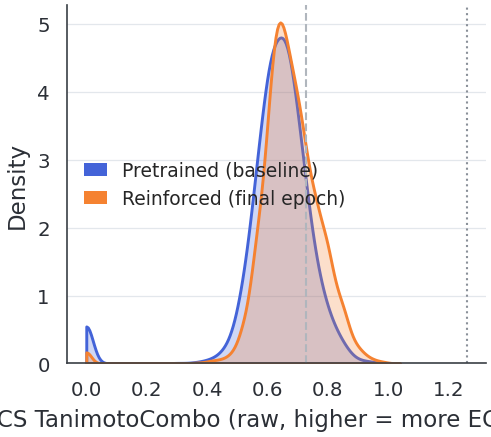

In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
import _figstyle as fs

fs.apply_style()
vb = df_baseline[df_baseline["Valid"] == 1]
vr = df_rl[df_rl["Valid"] == 1]

# 1. raw TanimotoCombo distribution
fig, ax = fs.new_ax()
for arm, d in (("baseline", vb), ("reinforced", vr)):
    sns.kdeplot(d[ROCS_KEY], ax=ax, color=fs.ARM[arm], fill=True, alpha=0.25,
                linewidth=1.4, cut=0)
ax.axvline(ROCS_THRESHOLD, color=fs.ZERO, linestyle="--", linewidth=1.0)
ax.axvline(cfg.SELF_SCORE_CEILING, color=fs.MUTED, linestyle=":", linewidth=1.0)
ax.set_xlabel("ROCS TanimotoCombo (raw, higher = more EGCG-like)")
ax.set_ylabel("Density")
fs.arm_legend(ax)
print(fs.save(fig, "01_tanimotocombo_distribution"))
plt.show()

/home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/panels/02_sascore_distribution.png


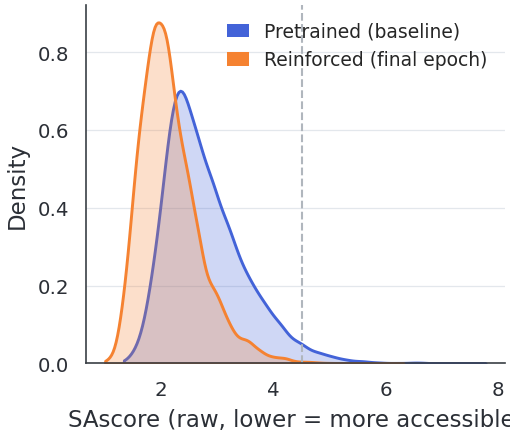

In [20]:
# 2. raw SA distribution
fig, ax = fs.new_ax()
for arm, d in (("baseline", vb), ("reinforced", vr)):
    sns.kdeplot(d["SA_raw"].dropna(), ax=ax, color=fs.ARM[arm], fill=True,
                alpha=0.25, linewidth=1.4, cut=0)
ax.axvline(cfg.RAW_SA_CUTOFF, color=fs.ZERO, linestyle="--", linewidth=1.0)
ax.set_xlabel("SAscore (raw, lower = more accessible)")
ax.set_ylabel("Density")
fs.arm_legend(ax)
print(fs.save(fig, "02_sascore_distribution"))
plt.show()

/home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/panels/03_training_curve.png


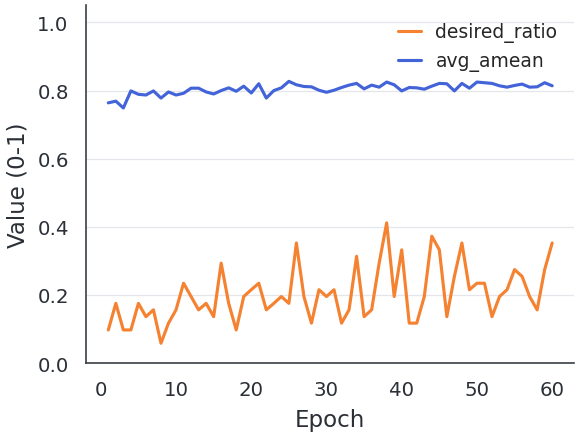

In [21]:
# 3. training curve
fit_tsv = Path(f"{cfg.MONITOR_BASE}_fit.tsv")
if fit_tsv.exists():
    dfit = pd.read_csv(fit_tsv, sep="\t")
    fig, ax = fs.new_ax(w=4.2)
    if "desired_ratio" in dfit:
        ax.plot(dfit["Epoch"], dfit["desired_ratio"], color=fs.ARM["reinforced"],
                linewidth=1.5, label="desired_ratio")
    if "avg_amean" in dfit:
        ax.plot(dfit["Epoch"], dfit["avg_amean"], color=fs.ARM["baseline"],
                linewidth=1.5, label="avg_amean")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Value (0-1)")
    ax.set_ylim(0, 1.05)
    ax.legend()
    print(fs.save(fig, "03_training_curve"))
    plt.show()
else:
    print(f"no fit log at {fit_tsv}")

/home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/panels/04_rocs_vs_sa_scatter.png


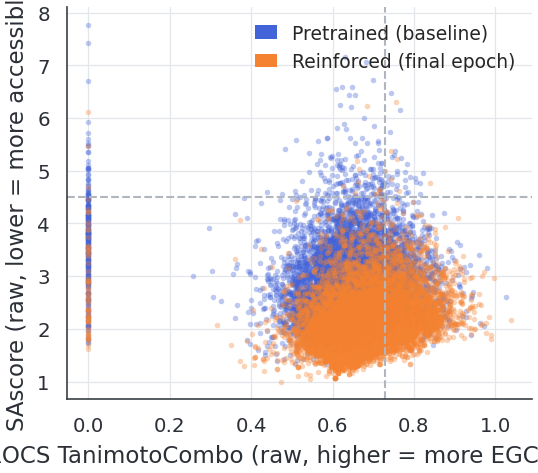

In [22]:
# 4. ROCS vs SA scatter -- are BOTH objectives moving, or one at the other's cost?
fig, ax = fs.new_ax(w=4.0, h=3.4)
for arm, d in (("baseline", vb), ("reinforced", vr)):
    ax.scatter(d[ROCS_KEY], d["SA_raw"], s=7, alpha=0.35, linewidths=0,
               color=fs.ARM[arm])
ax.axvline(ROCS_THRESHOLD, color=fs.ZERO, linestyle="--", linewidth=1.0)
ax.axhline(cfg.RAW_SA_CUTOFF, color=fs.ZERO, linestyle="--", linewidth=1.0)
ax.set_xlabel("ROCS TanimotoCombo (raw, higher = more EGCG-like)")
ax.set_ylabel("SAscore (raw, lower = more accessible)")
ax.grid(axis="x", visible=True)
fs.arm_legend(ax)
print(fs.save(fig, "04_rocs_vs_sa_scatter"))
plt.show()

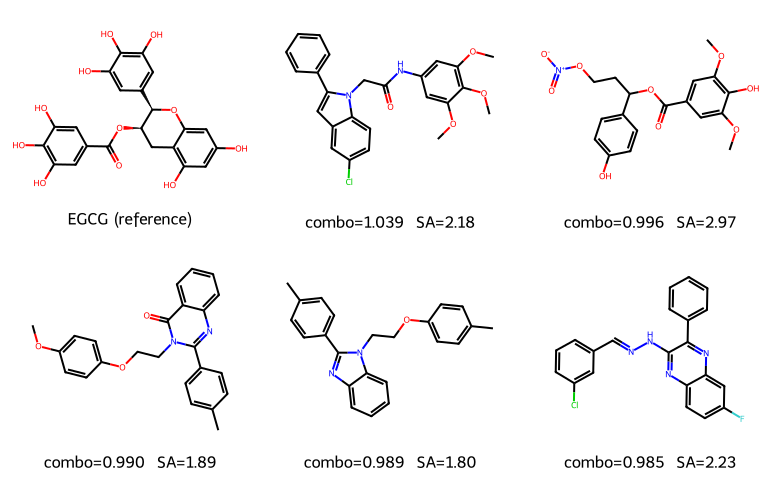

In [23]:
# 5. top-scoring reinforced structures beside EGCG
top = (vr.sort_values(ROCS_KEY, ascending=False)
         .drop_duplicates("canonical")
         .head(5))
mols = [Chem.MolFromSmiles(desc["canonical_smiles"])] + \
       [Chem.MolFromSmiles(s) for s in top["canonical"]]
legends = ["EGCG (reference)"] + [
    f"combo={r[ROCS_KEY]:.3f}  SA={r['SA_raw']:.2f}" for _, r in top.iterrows()
]
Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(260, 240), legends=legends)

### Trajectory: does longer RL reverse the shrinkage, or amplify it?

The v1 run (20 epochs x 256) ended with median heavy atoms down 27 -> 18 and
median MW down 377 -> 254, while shape similarity fell slightly. This run
raises the RL budget specifically to test whether more exploration eventually
finds large, EGCG-like molecules instead.

`FileMonitor` logs the per-epoch validation sample (`n_samples/10` molecules)
with its scores, so molecular size and shape can be tracked **across training**
rather than only at the endpoints. If the shrinkage reverses, it shows here.

Each point is a small sample, so read the trend, not the individual epochs.

In [24]:
from rdkit.Chem import Descriptors

_smi_tsv = Path(f"{cfg.MONITOR_BASE}_smiles.tsv")
traj = None
if _smi_tsv.exists():
    _d = pd.read_csv(_smi_tsv, sep="	")
    _d = _d[_d["Valid"] == 1].copy()
    _mols = [Chem.MolFromSmiles(x) for x in _d["SMILES"]]
    _d["heavy"] = [m.GetNumHeavyAtoms() if m else np.nan for m in _mols]
    _d["mw"] = [Descriptors.MolWt(m) if m else np.nan for m in _mols]
    traj = _d.groupby("Epoch").agg(
        median_heavy=("heavy", "median"),
        median_mw=("mw", "median"),
        median_rocs=(ROCS_KEY, "median"),
        n=("heavy", "size"),
    ).reset_index()
    traj.to_csv(cfg.OUTPUT_DIR / "epoch_trajectory.csv", index=False)
    print(traj.to_string(index=False))
else:
    print(f"no monitor SMILES log at {_smi_tsv}")

 Epoch  median_heavy  median_mw  median_rocs  n
     1          24.5   342.8420       0.6420 50
     2          23.5   337.3380       0.6520 48
     3          24.0   339.4170       0.6375 48
     4          23.0   340.4040       0.6450 49
     5          24.0   333.4350       0.6430 47
     6          21.0   317.8965       0.6610 50
     7          23.0   330.0635       0.6415 50
     8          23.0   337.3050       0.6270 47
     9          25.0   351.1060       0.6590 46
    10          24.0   343.8780       0.6510 48
    11          23.0   330.4380       0.6560 47
    12          23.0   316.3570       0.6640 48
    13          23.0   332.3550       0.6490 49
    14          24.0   333.9350       0.6730 50
    15          24.0   356.9615       0.6565 50
    16          26.0   356.3820       0.6530 51
    17          23.0   324.4050       0.6620 49
    18          23.0   325.3930       0.6360 51
    19          24.0   344.4140       0.6660 49
    20          25.0   351.7930       0.

/home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/panels/06_size_trajectory.png


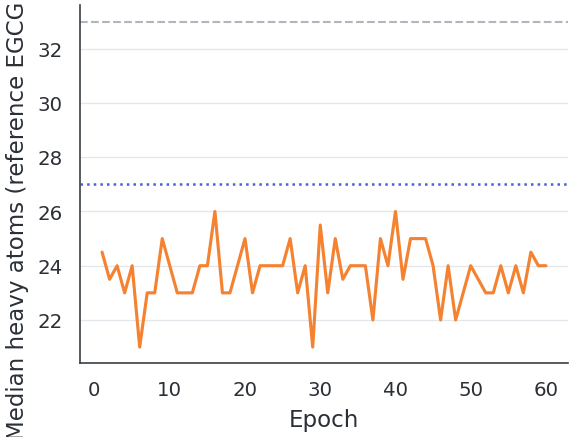

In [25]:
# 06. molecular size across training, against EGCG's own size
if traj is not None and len(traj) > 1:
    fig, ax = fs.new_ax(w=4.2)
    ax.plot(traj["Epoch"], traj["median_heavy"], color=fs.ARM["reinforced"], linewidth=1.5)
    ax.axhline(cfg.EGCG_HEAVY_ATOMS, color=fs.ZERO, linestyle="--", linewidth=1.0)
    ax.axhline(m_baseline_heavy, color=fs.ARM["baseline"], linestyle=":", linewidth=1.2)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Median heavy atoms (reference EGCG = 33)")
    print(fs.save(fig, "06_size_trajectory"))
    plt.show()

/home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/panels/07_shape_trajectory.png


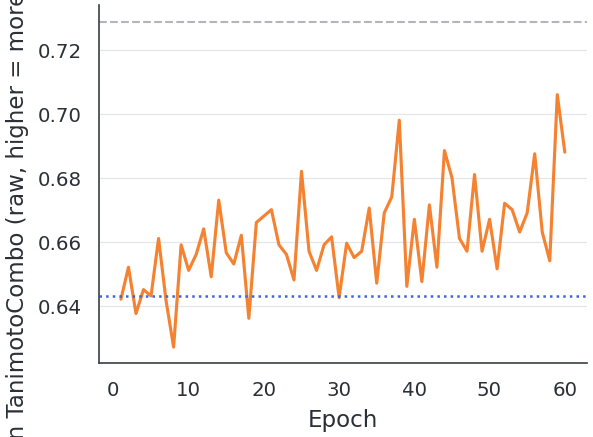

In [26]:
# 07. shape across training
if traj is not None and len(traj) > 1:
    fig, ax = fs.new_ax(w=4.2)
    ax.plot(traj["Epoch"], traj["median_rocs"], color=fs.ARM["reinforced"], linewidth=1.5)
    ax.axhline(m_baseline["median_rocs"], color=fs.ARM["baseline"], linestyle=":", linewidth=1.2)
    ax.axhline(ROCS_THRESHOLD, color=fs.ZERO, linestyle="--", linewidth=1.0)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Median TanimotoCombo (raw, higher = more EGCG-like)")
    print(fs.save(fig, "07_shape_trajectory"))
    plt.show()

## Record

Everything needed to reproduce: revision, module locations, hashes, seeds,
scoring parameters, thresholds, metrics.

In [27]:
out_json = cfg.OUTPUT_DIR / "provenance.json"
out_json.write_text(json.dumps(PROVENANCE, indent=2, default=str))

df_baseline.to_csv(cfg.OUTPUT_DIR / "baseline_raw.csv.gz", index=False)
df_rl.to_csv(cfg.OUTPUT_DIR / "reinforced_raw.csv.gz", index=False)
df_calib.to_csv(cfg.OUTPUT_DIR / "calibration_raw.csv.gz", index=False)
comparison.to_csv(cfg.OUTPUT_DIR / "comparison.csv")

print(f"wrote {out_json}")
for p in sorted(cfg.OUTPUT_DIR.glob("*")):
    print(f"  {p.name}")

wrote /home/fulopj/drx-run/DrugEx/.worktrees/egcg/tutorial/advanced/rocs/egcg/runs/provenance.json
  EGCG_rdkit_reinforced.pkg
  EGCG_rdkit_reinforced_final_epoch.pkg
  EGCG_rdkit_reinforced_fit.log
  EGCG_rdkit_reinforced_fit.tsv
  EGCG_rdkit_reinforced_smiles.tsv
  baseline_raw.csv.gz
  calibration_raw.csv.gz
  comparison.csv
  epoch_trajectory.csv
  provenance.json
  reinforced_raw.csv.gz
